# Lab 02 — Data Visualization & Analysis for Cybersecurity
**Course:** IA for Cybersecurity — 3rd Year, Second Cycle, Option CyS (ESI Sidi-Bel-Abbès) — Dr R. Bousmaha
**Use case chosen:** *Analysis of log data* — detecting a **directory-enumeration scan** in a web-server access log
**Tool:** Python (pandas, NumPy, Matplotlib, Seaborn)

---

### How this notebook maps to the lab tasks

| Lab task | Where |
|---|---|
| 1. Choose one use case | Section 1 |
| 2. Select / simulate a dataset | Section 2 |
| 3. Choose a tool | Section 3 |
| 4. Explore and analyse the data | Section 4 |
| 5. Inject / identify one anomaly and show where it is | Section 5 |
| 6. At least two visualizations | Section 6 (three figures) |
| 7. One simple detection rule | Section 7 |
| 8. Evaluate the rule on anomalous **and** normal data | Section 8 |
| 9. Present and explain the main findings | Section 9 |

Run the notebook top to bottom (**Kernel → Restart & Run All**). It needs no internet access and no external dataset; everything is generated locally with fixed random seeds, so results are exactly reproducible.

## 1. Use case (Task 1)

**Chosen use case: Analysis of log data.**

**Why this one?**
- Logs are the raw material of every SOC / SIEM; the use case is easy to motivate and to defend.
- A web-server access log has a *real, standard text format* (Apache/Nginx "combined"), so we can show the full pipeline: **raw text → parsing → table → visualization → rule**.
- The anomaly (a directory-enumeration scan, e.g. produced by `gobuster`, `dirb`, `ffuf`) is a very common first step of a web attack and has a clear, explainable signature: **a single IP generating a burst of HTTP 404 errors**.

**The attack we study.** Before attacking a website, an attacker often does not know which pages exist. A tool takes a wordlist (`admin`, `backup`, `.env`, ...) and requests every word, hoping for a response other than *404 Not Found*. Almost every guess fails, so the log shows a sudden burst of 404 responses from one source address.

## 3. Tool (Task 3)  — *(placed before the data because the generator needs the libraries)*

**Python** with:
- `pandas` — parsing, grouping, per-window features
- `NumPy` — seeded random generation
- `Matplotlib` / `Seaborn` — plots

Reasons: the whole analysis is reproducible in one notebook, needs no server (unlike Kibana/ELK), and every step can be shown line by line during the defence.

In [1]:
import re, json
from datetime import datetime, timedelta
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LogNorm
import seaborn as sns
from IPython.display import display

SEED = 2026                       # one seed -> fully reproducible results
DATA_DIR, FIG_DIR = Path("data"), Path("figures")
DATA_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

DAY1 = datetime(2026, 5, 20)      # analysis day  (normal traffic + injected anomaly)
DAY2 = datetime(2026, 5, 21)      # held-out day  (normal traffic only)

sns.set_theme(style="whitegrid", context="notebook")
BLUE, RED, ORANGE = "#0B6E93", "#C0392B", "#E67E22"   # blue = normal, red = anomaly, orange = benign-but-noisy

## 2. Dataset (Task 2) — simulated web-server access log

**Decision: simulate the dataset** (allowed by the lab). Reasons:
1. We *know the ground truth* (which request belongs to the attack), which is what makes a proper evaluation of the detection rule possible. Public datasets rarely give clean labels at request level.
2. Total control over the "hard cases" that test whether the rule is sound (see below).
3. No privacy/legal problem: all IP addresses come from the **RFC 5737 documentation ranges** (`192.0.2.0/24`, `198.51.100.0/24`, `203.0.113.0/24`), which are reserved and never belong to a real host.

**What is simulated (one 24-hour day = one log file):**

| Actor | Behaviour | Why it is in the dataset |
|---|---|---|
| ~80 ordinary visitors | Sessions of 2–7 page views, each with a few images/CSS/JS files, daytime-heavy; ~2 % of page views hit a stale link (404) | The **normal baseline** |
| `ExampleBot` crawler | 5 bursts of ~70 requests in ~1 minute, almost no 404 | **Hard negative #1:** high *volume* but harmless — a naive "requests per minute" rule would raise a false alarm |
| Uptime monitor | `GET /health` every 5 min | Periodic machine traffic |
| One user on a broken legacy page | A page whose images are all missing → ~12 404 in a few seconds | **Hard negative #2:** a legitimate burst of 404s that is smaller than the attack |
| **Attacker** (day 1 only) | `gobuster`-style scan, ~650 probes in ~3 min at 03:12 | **The injected anomaly** |

Two files are produced:
- `access_day1.log` — normal traffic **+ the attack** (analysis day, used to design/tune the rule);
- `access_day2.log` — a **different** normal day (other seed), used only to test that the rule does not raise false alarms on unseen normal data.

Ground-truth labels are stored in a **separate** CSV. They are used only for plotting and evaluation — **never by the detection rule**.

In [2]:
# ----------------------------------------------------------------------
# Description of the (fictional) web site and of normal user behaviour
# ----------------------------------------------------------------------
HOST = "https://shop.example.com"
PAGES = ["/", "/products", "/products/laptops", "/products/phones", "/blog",
         "/blog/post-1", "/blog/post-2", "/blog/post-3", "/about", "/contact", "/cart", "/login"]
PAGE_W = np.array([22, 12, 8, 8, 8, 4, 4, 4, 5, 4, 6, 8], dtype=float)   # popularity of each page
PAGE_W /= PAGE_W.sum()
ASSETS = ["/css/main.css", "/js/app.js", "/images/logo.png", "/images/banner.jpg",
          "/images/product1.jpg", "/images/product2.jpg", "/favicon.ico"]
STALE_PATHS = ["/old-offer", "/blog/post-99", "/products/tablets", "/img/promo.png", "/press", "/news/2019"]
BROWSERS = [
    "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124.0 Safari/537.36",
    "Mozilla/5.0 (X11; Linux x86_64; rv:125.0) Gecko/20100101 Firefox/125.0",
    "Mozilla/5.0 (Macintosh; Intel Mac OS X 14_4) AppleWebKit/605.1.15 (KHTML, like Gecko) Version/17.4 Safari/605.1.15",
    "Mozilla/5.0 (Linux; Android 14; Pixel 8) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124.0 Mobile Safari/537.36",
    "Mozilla/5.0 (iPhone; CPU iPhone OS 17_4 like Mac OS X) AppleWebKit/605.1.15 (KHTML, like Gecko) Version/17.4 Mobile/15E148 Safari/604.1",
]
# relative number of session starts per hour of the day (quiet at night, busy 09:00-17:00)
HOUR_W = np.array([1,1,1,1,1,2,3,5,8,10,11,11,10,10,11,11,10,8,6,5,4,3,2,1], dtype=float)
HOUR_W /= HOUR_W.sum()
N_SESSIONS = 420

CRAWLER_IP = "198.51.100.77"
CRAWLER_UA = "Mozilla/5.0 (compatible; ExampleBot/1.0; +http://example.org/bot)"
MONITOR_IP, MONITOR_UA = "192.0.2.250", "UptimeMonitor/1.0"


def size_for(rng, status, kind):
    """Response size in bytes (Apache logs fixed-size error pages, so these are constants)."""
    fixed = {404: 196, 301: 231, 302: 295, 403: 199, 500: 527, 304: 0}
    if status in fixed:
        return fixed[status]
    return int(rng.integers(3000, 15000) if kind == "page" else rng.integers(500, 60000))


def rec(ts, ip, method, path, status, size, ua, referer="-", label=0, actor="visitor"):
    """One log record. `label` and `actor` are ground truth and are NOT written to the log file."""
    return dict(ts=ts, ip=ip, method=method, path=path, status=int(status), size=int(size),
                referer=referer, ua=ua, label=label, actor=actor)


def visitor_session(rng, ip, ua, t0):
    """One human browsing session: a few page views, each followed by its assets."""
    out, t, prev = [], t0, None
    for _ in range(int(rng.integers(2, 8))):
        page = str(rng.choice(PAGES, p=PAGE_W))
        status = int(rng.choice([200, 301, 404, 500], p=[0.95, 0.025, 0.02, 0.005]))
        if status == 404:                                   # clicked a stale link
            page = str(rng.choice(STALE_PATHS))
        out.append(rec(t, ip, "GET", page, status, size_for(rng, status, "page"), ua,
                       HOST + prev if prev else "-"))
        if status == 200:
            for a in rng.choice(ASSETS, size=int(rng.integers(2, 5)), replace=False):
                st = int(rng.choice([200, 304], p=[0.7, 0.3]))
                out.append(rec(t + timedelta(seconds=float(rng.uniform(0.05, 1.5))), ip, "GET", str(a),
                               st, size_for(rng, st, "asset"), ua, HOST + page))
        if page == "/login" and status == 200 and rng.random() < 0.6:     # user submits the login form
            st = 302 if rng.random() < 0.9 else 200
            out.append(rec(t + timedelta(seconds=float(rng.uniform(5, 20))), ip, "POST", "/login",
                           st, size_for(rng, st, "page"), ua, HOST + "/login"))
        prev = page
        t += timedelta(seconds=float(rng.uniform(3, 40)))                 # think time between pages
    return out


def simulate_normal_day(day, seed, near_miss):
    """24 h of legitimate traffic. `near_miss` = (ip, n_missing_images, time_of_day)."""
    rng = np.random.default_rng(seed)
    recs = []

    # 1) ordinary visitors
    pool = [f"192.0.2.{i}" for i in range(1, 99)] + [f"203.0.113.{i}" for i in range(1, 99)]
    visitors = [str(x) for x in rng.choice(pool, size=80, replace=False)]
    ua_of = {ip: str(rng.choice(BROWSERS)) for ip in visitors}
    for _ in range(N_SESSIONS):
        ip = str(rng.choice(visitors))
        hour = int(rng.choice(24, p=HOUR_W))
        t0 = day + timedelta(hours=hour, minutes=int(rng.integers(0, 60)), seconds=int(rng.integers(0, 60)))
        recs += visitor_session(rng, ip, ua_of[ip], t0)

    # 2) benign crawler: 5 bursts of 70 requests, ~1 minute each, ~3 % 404
    for start_h in (1.5, 6.0, 10.5, 15.0, 21.0):
        t = day + timedelta(hours=start_h)
        for k in range(70):
            path = "/robots.txt" if k == 0 else str(rng.choice(PAGES))
            st = int(rng.choice([200, 304, 404], p=[0.90, 0.07, 0.03]))
            if st == 404:
                path = str(rng.choice(STALE_PATHS))
            recs.append(rec(t, CRAWLER_IP, "GET", path, st, size_for(rng, st, "page"), CRAWLER_UA, actor="crawler"))
            t += timedelta(seconds=float(rng.uniform(0.5, 1.2)))

    # 3) uptime monitor every 5 minutes
    for m in range(0, 1440, 5):
        recs.append(rec(day + timedelta(minutes=m, seconds=13), MONITOR_IP, "GET", "/health", 200, 15,
                        MONITOR_UA, actor="monitor"))

    # 4) a legitimate user opens a legacy page whose images are all missing -> burst of benign 404s
    nm_ip, nm_n, nm_time = near_miss
    t = day + nm_time
    recs.append(rec(t, nm_ip, "GET", "/legacy/gallery.html", 200, 8200, BROWSERS[0], actor="broken-page"))
    for k in range(nm_n):
        t += timedelta(seconds=float(rng.uniform(0.1, 0.4)))
        recs.append(rec(t, nm_ip, "GET", f"/legacy/img/photo{k+1}.jpg", 404, 196, BROWSERS[0],
                        HOST + "/legacy/gallery.html", actor="broken-page"))

    df = pd.DataFrame(recs)
    df = df[df["ts"] < day + timedelta(hours=24)]            # keep exactly one calendar day
    return df.sort_values("ts", kind="stable").reset_index(drop=True)

In [3]:
# ----------------------------------------------------------------------
# THE INJECTED ANOMALY: a gobuster-style directory enumeration (day 1 only)
# ----------------------------------------------------------------------
ATTACKER_IP, ATTACK_UA = "198.51.100.23", "gobuster/3.6"

WORDS = """admin administrator login logout register signup signin dashboard panel console manager
manage control cpanel webmail mail user users account accounts profile member customer customers
order orders cart checkout payment billing invoice config configuration conf settings setup install
installer upgrade update backup backups dump db database sql mysql phpmyadmin pma adminer data dev
test testing staging beta demo old new temp tmp cache logs log error debug status server-status
server-info info phpinfo api docs help support uploads upload files download media images assets
static include lib vendor src app cgi-bin bin scripts private secret internal intranet portal blog
wp-admin wp-login wp-content .git .env .htaccess .htpasswd .svn robots sitemap readme license""".split()
EXTS = ["", ".php", ".bak", ".zip", ".txt", ".old"]          # gobuster -x php,bak,zip,txt,old
ATTACK_PATHS = [f"/{w}{e}" for w in WORDS for e in EXTS]

# the few guesses that happen to exist on the server (everything else answers 404)
EXISTING = {"/admin": 302, "/login": 200, "/blog": 200, "/uploads": 301,
            "/backup.zip": 403, "/.env": 403, "/server-status": 403, "/.htaccess": 403, "/.htpasswd": 403}


def simulate_attack(day, seed=99):
    rng = np.random.default_rng(seed)
    start = day + timedelta(hours=3, minutes=12, seconds=25)          # 03:12:25, nobody is awake
    offsets = np.cumsum(rng.exponential(0.25, size=len(ATTACK_PATHS)))  # ~4 requests per second
    out = []
    for off, path in zip(offsets, ATTACK_PATHS):
        status = EXISTING.get(path, 404)
        size = {404: 196, 403: 199, 301: 231, 302: 295}.get(status, 4200)
        out.append(rec(start + timedelta(seconds=float(off)), ATTACKER_IP, "GET", path, status, size,
                       ATTACK_UA, actor="attacker", label=1))
    return pd.DataFrame(out)


def write_log(df, path):
    """Write records in the Apache/Nginx *combined* log format (plain text, one line per request)."""
    with open(path, "w", encoding="utf-8") as f:
        for r in df.itertuples(index=False):
            ts = r.ts.strftime("%d/%b/%Y:%H:%M:%S +0000")
            size = r.size if r.size > 0 else "-"
            f.write(f'{r.ip} - - [{ts}] "{r.method} {r.path} HTTP/1.1" {r.status} {size} "{r.referer}" "{r.ua}"\n')


# ---- day 1 = normal + attack ------------------------------------------------------------
normal1 = simulate_normal_day(DAY1, seed=SEED, near_miss=("192.0.2.99", 12, timedelta(hours=14, minutes=37, seconds=10)))
attack  = simulate_attack(DAY1)
day1 = pd.concat([normal1, attack], ignore_index=True).sort_values("ts", kind="stable").reset_index(drop=True)
write_log(day1, DATA_DIR / "access_day1.log")
day1[["label", "actor"]].rename_axis("line_no").to_csv(DATA_DIR / "ground_truth_day1.csv")   # labels kept SEPARATE

# ---- day 2 = a different, purely normal day (held-out test) -----------------------------
normal2 = simulate_normal_day(DAY2, seed=7, near_miss=("203.0.113.200", 14, timedelta(hours=10, minutes=21, seconds=40)))
write_log(normal2, DATA_DIR / "access_day2.log")

print(f"day 1 log: {len(day1):>5} lines  ({len(attack)} of them belong to the attack)")
print(f"day 2 log: {len(normal2):>5} lines  (normal only)")

day 1 log:  8774 lines  (654 of them belong to the attack)
day 2 log:  7799 lines  (normal only)


## 4. Parsing and exploration (Task 4)

### 4.1 From raw text to a table
A log line is just text. We parse it with a regular expression that follows the *combined* format:

`IP ident user [timestamp] "METHOD /path PROTOCOL" status bytes "referer" "user-agent"`

Every line must parse; we count failures to be sure no data is silently lost.

In [4]:
LOG_RE = re.compile(
    r'^(?P<ip>\S+) \S+ \S+ \[(?P<ts>[^\]]+)\] '
    r'"(?P<method>[A-Z]+) (?P<path>\S+) (?P<proto>[^"]+)" '
    r'(?P<status>\d{3}) (?P<size>\d+|-) '
    r'"(?P<referer>[^"]*)" "(?P<ua>[^"]*)"$'
)

def parse_log(path):
    """Parse an access log into a DataFrame. Returns (dataframe, number_of_unparsed_lines)."""
    rows, bad = [], 0
    with open(path, encoding="utf-8") as f:
        for n, line in enumerate(f):
            m = LOG_RE.match(line.rstrip("\n"))
            if m is None:
                bad += 1
                continue
            d = m.groupdict()
            d["line_no"] = n
            rows.append(d)
    df = pd.DataFrame(rows)
    df["ts"] = pd.to_datetime(df["ts"], format="%d/%b/%Y:%H:%M:%S %z", utc=True).dt.tz_localize(None)
    df["status"] = df["status"].astype(int)
    df["size"] = df["size"].replace("-", "0").astype(int)
    df["minute"] = df["ts"].dt.floor("min")      # 1-minute bucket used later by the rule
    df["hour"] = df["ts"].dt.hour
    return df, bad

# a look at what the raw text really looks like (3 normal lines, then 3 attack lines)
raw = (DATA_DIR / "access_day1.log").read_text(encoding="utf-8").splitlines()
gt_raw = pd.read_csv(DATA_DIR / "ground_truth_day1.csv")
print("RAW NORMAL LINES")
for i in gt_raw.index[gt_raw["actor"] == "visitor"][100:103]:
    print("  ", raw[i])
print("\nRAW LINES FROM THE ATTACK")
for i in gt_raw.index[gt_raw["label"] == 1][:3]:
    print("  ", raw[i])

RAW NORMAL LINES
   203.0.113.36 - - [20/May/2026:00:58:01 +0000] "GET /favicon.ico HTTP/1.1" 200 12578 "https://shop.example.com/products" "Mozilla/5.0 (iPhone; CPU iPhone OS 17_4 like Mac OS X) AppleWebKit/605.1.15 (KHTML, like Gecko) Version/17.4 Mobile/15E148 Safari/604.1"
   203.0.113.16 - - [20/May/2026:01:32:28 +0000] "GET /blog/post-2 HTTP/1.1" 200 13839 "-" "Mozilla/5.0 (Linux; Android 14; Pixel 8) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124.0 Mobile Safari/537.36"
   203.0.113.16 - - [20/May/2026:01:32:28 +0000] "GET /css/main.css HTTP/1.1" 304 - "https://shop.example.com/blog/post-2" "Mozilla/5.0 (Linux; Android 14; Pixel 8) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124.0 Mobile Safari/537.36"

RAW LINES FROM THE ATTACK
   198.51.100.23 - - [20/May/2026:03:12:25 +0000] "GET /admin HTTP/1.1" 302 295 "-" "gobuster/3.6"
   198.51.100.23 - - [20/May/2026:03:12:25 +0000] "GET /admin.php HTTP/1.1" 404 196 "-" "gobuster/3.6"
   198.51.100.23 - - [20/May/2026:03:12:25 +000

In [5]:
d1_log, bad1 = parse_log(DATA_DIR / "access_day1.log")
d2, bad2 = parse_log(DATA_DIR / "access_day2.log")
assert bad1 == 0 and bad2 == 0, "some lines could not be parsed"
assert len(d1_log) == len(day1) and len(d2) == len(normal2)

# attach ground truth to day 1 (for plotting / evaluation only)
gt = pd.read_csv(DATA_DIR / "ground_truth_day1.csv")
d1 = d1_log.merge(gt, on="line_no", how="left")
assert d1["label"].notna().all()
d1["label"] = d1["label"].astype(int)

print(f"Parsed day 1: {len(d1)} requests, {bad1} unparsed lines")
print(f"Parsed day 2: {len(d2)} requests, {bad2} unparsed lines\n")
display(d1[["ts", "ip", "method", "path", "status", "size", "ua"]].head())

Parsed day 1: 8774 requests, 0 unparsed lines
Parsed day 2: 7799 requests, 0 unparsed lines



,ts,ip,method,path,status,size,ua
0,2026-05-20 00:00:13,192.0.2.250,GET,/health,200,15,UptimeMonitor/1.0
1,2026-05-20 00:03:57,203.0.113.48,GET,/,200,12841,Mozilla/5.0 (iPhone; CPU iPhone OS 17_4 like M...
2,2026-05-20 00:03:57,203.0.113.48,GET,/images/banner.jpg,200,10525,Mozilla/5.0 (iPhone; CPU iPhone OS 17_4 like M...
3,2026-05-20 00:03:57,203.0.113.48,GET,/css/main.css,304,0,Mozilla/5.0 (iPhone; CPU iPhone OS 17_4 like M...
4,2026-05-20 00:03:57,203.0.113.48,GET,/js/app.js,200,17199,Mozilla/5.0 (iPhone; CPU iPhone OS 17_4 like M...


### 4.2 First exploration (day 1)
We look at the basic shape of the data: status codes, who talks the most, and who produces errors.

In [6]:
print(f"Time span      : {d1.ts.min()}  ->  {d1.ts.max()}")
print(f"Requests       : {len(d1)}")
print(f"Distinct IPs   : {d1.ip.nunique()}\n")

print("HTTP status code distribution")
display(d1["status"].value_counts().sort_index().rename("requests").to_frame())

print("Top 5 IPs by NUMBER OF REQUESTS")
display(d1["ip"].value_counts().head(5).rename("requests").to_frame())

print("Top 5 IPs by NUMBER OF 404 ERRORS")
display(d1[d1.status == 404]["ip"].value_counts().head(5).rename("404 errors").to_frame())

Time span      : 2026-05-20 00:00:13  ->  2026-05-20 23:55:13
Requests       : 8774
Distinct IPs   : 83

HTTP status code distribution


,requests
status,
200,6261
301,53
302,93
304,1662
403,5
404,692
500,8


Top 5 IPs by NUMBER OF REQUESTS


,requests
ip,
198.51.100.23,654
198.51.100.77,350
192.0.2.250,288
192.0.2.40,239
192.0.2.25,215


Top 5 IPs by NUMBER OF 404 ERRORS


,404 errors
ip,
198.51.100.23,645
198.51.100.77,16
192.0.2.99,12
192.0.2.23,2
192.0.2.24,2


**What the exploration already tells us**
- Most traffic is `200`/`304` (normal page and file delivery) and the day follows a normal human rhythm (see Figure 1).
- Looking at **volume**, the scan is the busiest source, but the 2nd and 3rd busiest are the harmless crawler and the uptime monitor. Volume is a blunt signal: any threshold low enough to catch a slower scan also fires on harmless machines.
- Looking at **404 errors**, one address stands far above all the others (a few hundred 404 versus at most ~16 for any other IP). This is the lead we follow.

## 5. The anomaly (Task 5)

**Injected anomaly:** at **03:12:25** the address `198.51.100.23` starts a directory-enumeration scan with `gobuster`, sending one request for every entry of a wordlist (each word with 6 extensions). Nearly every guess fails with **404**; a handful of guesses hit real resources (`/admin`, `/login`, `/backup.zip`, `/.env`, ...).

Below, the anomaly is *located* precisely using the ground truth (time, source, volume, success rate).

In [7]:
atk = d1[d1["label"] == 1]
a_start, a_end = atk["ts"].min(), atk["ts"].max()
dur = (a_end - a_start).total_seconds()

print(f"Source IP           : {atk.ip.iloc[0]}")
print(f"User-Agent          : {atk.ua.iloc[0]}")
print(f"Start / end         : {a_start}  ->  {a_end}   ({dur:.0f} s)")
print(f"Requests            : {len(atk)}   (~{len(atk)/dur:.1f} requests/second)")
print(f"Distinct paths tried: {atk.path.nunique()}")
print(f"HTTP 404 share      : {(atk.status == 404).mean():.1%}\n")

print("Guesses that did NOT return 404 (what the attacker actually discovered):")
display(atk[atk.status != 404][["ts", "path", "status"]].reset_index(drop=True))

Source IP           : 198.51.100.23
User-Agent          : gobuster/3.6
Start / end         : 2026-05-20 03:12:25  ->  2026-05-20 03:15:21   (176 s)
Requests            : 654   (~3.7 requests/second)
Distinct paths tried: 654
HTTP 404 share      : 98.6%

Guesses that did NOT return 404 (what the attacker actually discovered):


,ts,path,status
0,2026-05-20 03:12:25,/admin,302
1,2026-05-20 03:12:27,/login,200
2,2026-05-20 03:13:27,/backup.zip,403
3,2026-05-20 03:14:10,/server-status,403
4,2026-05-20 03:14:21,/uploads,301
5,2026-05-20 03:14:56,/blog,200
6,2026-05-20 03:15:07,/.env,403
7,2026-05-20 03:15:07,/.htaccess,403
8,2026-05-20 03:15:09,/.htpasswd,403


## 6. Visualizations (Task 6)

Three figures. Each answers a different question:

| Figure | Question | Take-away |
|---|---|---|
| 1 | *When* does something unusual happen? | Time series of total volume vs. 404 errors |
| 2 | *What kind* of response is unusual, and when? | Heatmap status code × hour |
| 3 | *Who* produces the errors? | Top IPs by 404 count |

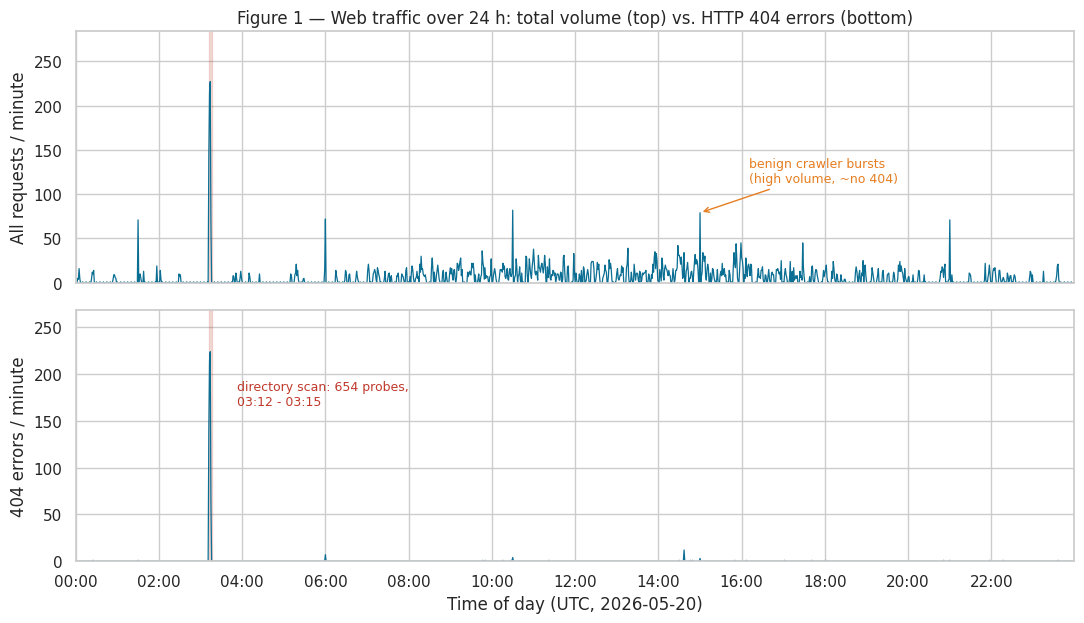

In [8]:
# ---------- Figure 1: requests per minute vs 404 per minute -------------------------------------
full_range = pd.date_range(DAY1, periods=1440, freq="min")                       # every minute of the day
req_pm  = d1.groupby("minute").size().reindex(full_range, fill_value=0)          # fill silent minutes with 0
e404_pm = d1[d1.status == 404].groupby("minute").size().reindex(full_range, fill_value=0)
assert req_pm.sum() == len(d1) and e404_pm.sum() == (d1.status == 404).sum()      # nothing lost by reindexing

a0 = a_start.floor("min")
a1 = a_end.floor("min") + pd.Timedelta(minutes=1)
crawl_pm = d1[d1.actor == "crawler"].groupby("minute").size()
cp = crawl_pm[crawl_pm.index.hour == 15].idxmax()                                 # one crawler burst, for the annotation

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.4), sharex=True)
ax1.plot(req_pm.index, req_pm.values, color=BLUE, lw=0.9)
ax1.set_ylabel("All requests / minute")
ax1.set_title("Figure 1 — Web traffic over 24 h: total volume (top) vs. HTTP 404 errors (bottom)")
ax1.set_ylim(0, req_pm.max() * 1.25)
ax1.annotate("benign crawler bursts\n(high volume, ~no 404)", xy=(cp, req_pm[cp]), xytext=(35, 22),
             textcoords="offset points", color=ORANGE, fontsize=9, arrowprops=dict(arrowstyle="->", color=ORANGE))

ax2.plot(e404_pm.index, e404_pm.values, color=BLUE, lw=0.9)
ax2.set_ylabel("404 errors / minute")
ax2.set_xlabel("Time of day (UTC, 2026-05-20)")
ax2.set_ylim(0, e404_pm.max() * 1.2)
ax2.annotate(f"directory scan: {len(atk)} probes,\n03:12 - 03:15", xy=(a1, e404_pm.max() * 0.8),
             xytext=(18, 0), textcoords="offset points", color=RED, fontsize=9, va="center")
for ax in (ax1, ax2):
    ax.axvspan(a0, a1, color=RED, alpha=0.18)
ax2.xaxis.set_major_locator(mdates.HourLocator(interval=2))
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax2.set_xlim(full_range[0], full_range[-1])
fig.tight_layout()
fig.savefig(FIG_DIR / "fig1_timeline.png", dpi=170, bbox_inches="tight")
plt.show()

**Reading Figure 1.** In the top panel the scan is the tallest spike, but the crawler (and busy browsing periods) also produce spikes, so *volume* is a blunt signal. In the bottom panel only **one** event stands out: the 404 count is almost flat (mostly 0–3 per minute, at most 12) except for the scan. **404 errors are a much cleaner signal than total volume.**

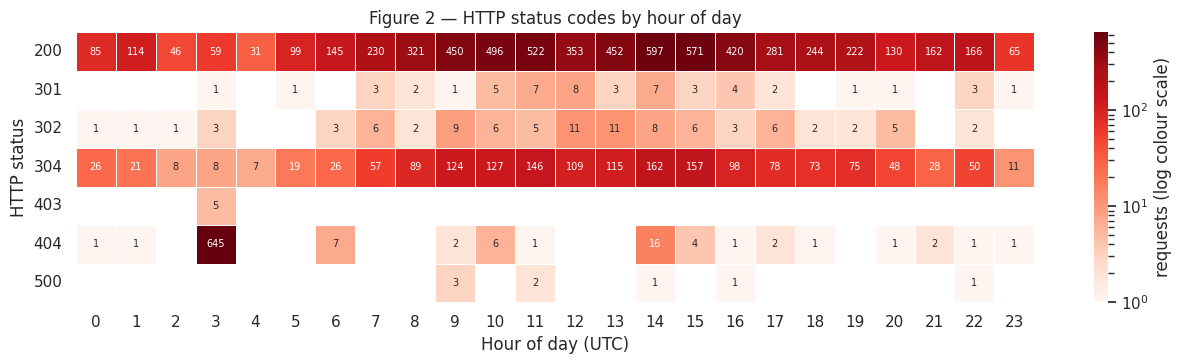

In [9]:
# ---------- Figure 2: heatmap status code x hour of day -----------------------------------------
pivot = (d1.pivot_table(index="status", columns="hour", values="line_no", aggfunc="count", fill_value=0)
           .reindex(columns=range(24), fill_value=0))

fig, ax = plt.subplots(figsize=(13, 3.8))
sns.heatmap(pivot, annot=True, fmt="d", annot_kws={"size": 7}, cmap="Reds",
            norm=LogNorm(vmin=1, vmax=int(pivot.values.max())), mask=(pivot == 0),
            linewidths=0.4, linecolor="white", cbar_kws={"label": "requests (log colour scale)"}, ax=ax)
ax.set_title("Figure 2 — HTTP status codes by hour of day")
ax.grid(False)
plt.setp(ax.get_yticklabels(), rotation=0)
ax.set_xlabel("Hour of day (UTC)")
ax.set_ylabel("HTTP status")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig2_heatmap.png", dpi=170, bbox_inches="tight")
plt.show()

**Reading Figure 2.** The `404` row is light for 23 hours and has one very dark cell at **hour 3**. The `403` row (*Forbidden*) exists **only** at hour 3: those are the scan guesses that hit protected files. Colour uses a *log scale* so that small counts stay readable next to the large one. The heatmap tells us the anomaly is about **error responses at night**, not about traffic in general.

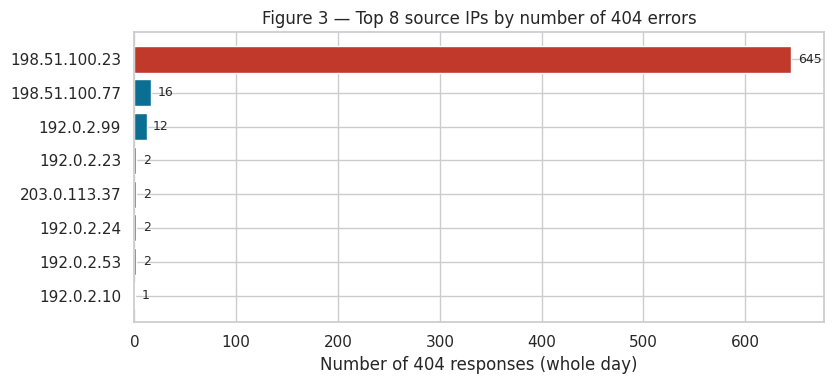

In [10]:
# ---------- Figure 3: who produces the 404 errors? ------------------------------------------------
top404 = d1[d1.status == 404].groupby("ip").size().sort_values(ascending=False).head(8)
colors = [RED if ip == ATTACKER_IP else BLUE for ip in top404.index]   # ground truth used for colouring only

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.barh(top404.index, top404.values, color=colors)
ax.invert_yaxis()
ax.set_xlabel("Number of 404 responses (whole day)")
ax.set_title("Figure 3 — Top 8 source IPs by number of 404 errors")
for y, v in enumerate(top404.values):
    ax.text(v + top404.max() * 0.01, y, str(v), va="center", fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig3_top_ips.png", dpi=170, bbox_inches="tight")
plt.show()

**Reading Figure 3.** One IP alone accounts for almost all 404 errors of the day; the next IPs have only a handful (the normal "stale link" errors). This identifies the **source** of the anomaly.

## 7. Detection rule (Task 7)

### 7.1 Choosing the feature
We aggregate the log into **windows**: one row per *(source IP, 1-minute window)* with two numbers:

- `n_req` — number of requests in the window (volume)
- `n_404` — number of `404` responses in the window

Figure 4 plots every window in this 2-D space. Three groups appear — and it shows *why* the rule uses `n_404` and not `n_req`.

In [11]:
def build_windows(df):
    """One row per (ip, 1-minute window) with simple counters. Works with or without ground truth."""
    d = df.assign(is404=(df["status"] == 404).astype(int))
    agg = dict(n_req=("status", "size"), n_404=("is404", "sum"))
    if "label" in d.columns:                       # ground truth (day 1 only) -> evaluation only
        agg["n_attack"] = ("label", "sum")
        agg["actor"] = ("actor", "first")
    return d.groupby(["ip", "minute"]).agg(**agg).reset_index()

w1 = build_windows(d1)
w2 = build_windows(d2)
print(f"day 1: {len(w1)} (IP, minute) windows   |   day 2: {len(w2)} windows")
display(w1.sort_values("n_404", ascending=False).head(6))

day 1: 1262 (IP, minute) windows   |   day 2: 1216 windows


,ip,minute,n_req,n_404,n_attack,actor
830,198.51.100.23,2026-05-20 03:14:00,227,224,227,attacker
829,198.51.100.23,2026-05-20 03:13:00,215,214,215,attacker
828,198.51.100.23,2026-05-20 03:12:00,144,142,144,attacker
831,198.51.100.23,2026-05-20 03:15:00,68,65,68,attacker
827,192.0.2.99,2026-05-20 14:37:00,13,12,0,broken-page
833,198.51.100.77,2026-05-20 06:00:00,70,7,0,crawler


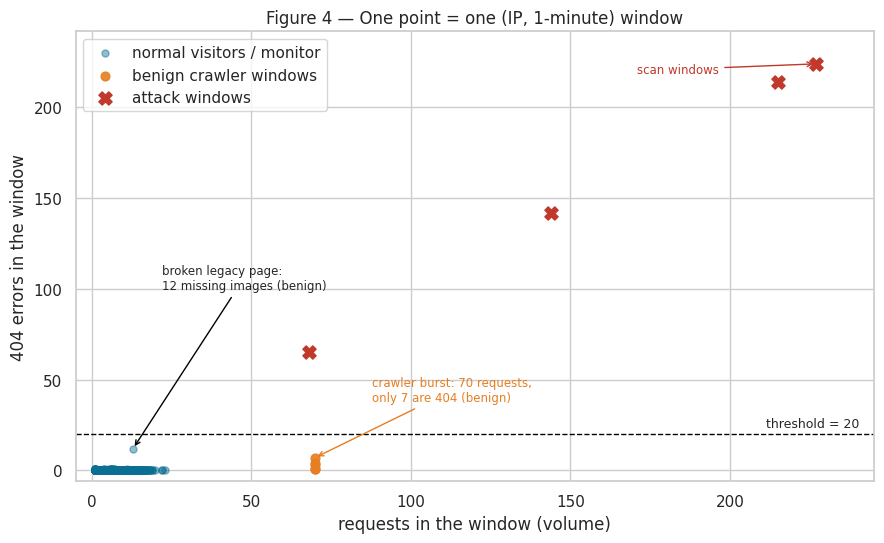

In [12]:
# ---------- Figure 4: feature space of all windows ------------------------------------------------
normal_w  = w1[(w1.n_attack == 0) & (w1.actor != "crawler")]
crawler_w = w1[w1.actor == "crawler"]
attack_w  = w1[w1.n_attack > 0]

fig, ax = plt.subplots(figsize=(9, 5.6))
ax.scatter(normal_w.n_req,  normal_w.n_404,  s=26, color=BLUE,   alpha=0.45, label="normal visitors / monitor")
ax.scatter(crawler_w.n_req, crawler_w.n_404, s=40, color=ORANGE, alpha=0.9,  label="benign crawler windows")
ax.scatter(attack_w.n_req,  attack_w.n_404,  s=90, color=RED,    marker="X", label="attack windows")

nm = w1[w1.actor == "broken-page"].sort_values("n_404").iloc[-1]
cw = crawler_w.sort_values("n_404").iloc[-1]
aw = attack_w.sort_values("n_404").iloc[-1]
ax.annotate(f"broken legacy page:\n{int(nm.n_404)} missing images (benign)", xy=(nm.n_req, nm.n_404),
            xytext=(22, 100), textcoords="data", fontsize=8.5, ha="left",
            arrowprops=dict(arrowstyle="->", color="black"))
ax.annotate(f"crawler burst: {int(cw.n_req)} requests,\nonly {int(cw.n_404)} are 404 (benign)", xy=(cw.n_req, cw.n_404),
            xytext=(88, 38), textcoords="data", fontsize=8.5, color=ORANGE, ha="left",
            arrowprops=dict(arrowstyle="->", color=ORANGE))
ax.annotate("scan windows", xy=(aw.n_req, aw.n_404), xytext=(-70, -4), textcoords="offset points",
            fontsize=8.5, color=RED, ha="right", va="center", arrowprops=dict(arrowstyle="->", color=RED))
ax.set_xlabel("requests in the window (volume)")
ax.set_ylabel("404 errors in the window")
ax.set_title("Figure 4 — One point = one (IP, 1-minute) window")
ax.set_xlim(-5, w1.n_req.max() * 1.08)
ax.set_ylim(-6, w1.n_404.max() * 1.08)
THRESHOLD = 20                                          # the rule's single parameter (justified in 7.2)
ax.axhline(THRESHOLD, color="black", ls="--", lw=1)
ax.text(w1.n_req.max() * 1.06, THRESHOLD + 4, f"threshold = {THRESHOLD}", ha="right", fontsize=9)
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig4_feature_space.png", dpi=170, bbox_inches="tight")
plt.show()

**Reading Figure 4.**
- **Blue** (normal): few requests *and* few 404 → bottom-left corner.
- **Orange** (crawler): lots of requests but still almost no 404 → far right, but *low*. A rule on `n_req` would flag it (false alarm); a rule on `n_404` does not.
- **Red** (scan): many 404 in one minute → clearly above everything else.
- The legitimate broken-page burst is the **highest normal point**: it is the "near miss" that tells us how high the threshold must be at least.

### 7.2 The rule

> **RULE:** *raise an alert if one source IP receives **more than 20** HTTP 404 responses within a 1-minute window.*

`alert  ⇔  n_404(ip, minute) > 20`

**Why these choices**

| Decision | Justification |
|---|---|
| Feature = number of **404** | Directly encodes the attacker's behaviour (guessing paths that do not exist); ignores harmless volume. |
| Grouped **per IP** | An attack comes from a source; per-IP counting avoids mixing it with the crowd. |
| **1-minute** window | Short enough to react fast; long enough to count a burst. Easy to explain. |
| Threshold **20** | Above the largest normal value observed (a broken page gives 12–14), far below every scan minute (at least 65 per minute). The sweep in Section 8 shows a wide safe zone, so the exact value is not fragile. |
| A rule, not a ML model | The lab asks for *one simple rule*; it is transparent, explainable to an analyst, and has no training needed. |

In [13]:
def apply_rule(w, feature="n_404", threshold=THRESHOLD):
    """Detection rule: alert when the counter of a window is strictly above the threshold."""
    return w[w[feature] > threshold].copy()

alerts1 = apply_rule(w1)
print(f"Alerts raised on DAY 1 (rule: n_404 > {THRESHOLD} per IP per minute): {len(alerts1)}")
display(alerts1[["ip", "minute", "n_req", "n_404"]].reset_index(drop=True))

Alerts raised on DAY 1 (rule: n_404 > 20 per IP per minute): 4


,ip,minute,n_req,n_404
0,198.51.100.23,2026-05-20 03:12:00,144,142
1,198.51.100.23,2026-05-20 03:13:00,215,214
2,198.51.100.23,2026-05-20 03:14:00,227,224
3,198.51.100.23,2026-05-20 03:15:00,68,65


## 8. Evaluation (Task 8)

We evaluate the rule on **both** kinds of data.

- **A — Anomalous data (day 1):** a labelled test. Every window is either *attack* (it contains at least one request of the scan) or *normal*. We count
  TP (attack window, alert), FN (attack window, no alert), FP (normal window, alert), TN (normal window, no alert).
- **B — Normal data (day 2):** a *different* normal day, never used to choose the threshold. Any alert here is a false alarm.

Metrics: **precision** = TP/(TP+FP) (how many alerts are real), **recall** = TP/(TP+FN) (how many attacks are caught), **FPR** = FP/(FP+TN) (how often normal windows are flagged), **F1** = harmonic mean of precision and recall.

In [14]:
def confusion(w, feature, threshold):
    pred = w[feature] > threshold
    act = w["n_attack"] > 0
    return (int((pred & act).sum()), int((pred & ~act).sum()),
            int((~pred & act).sum()), int((~pred & ~act).sum()))          # tp, fp, fn, tn

def metrics(tp, fp, fn, tn):
    precision = tp / (tp + fp) if (tp + fp) else float("nan")
    recall    = tp / (tp + fn) if (tp + fn) else float("nan")
    fpr       = fp / (fp + tn) if (fp + tn) else float("nan")
    f1 = 2 * precision * recall / (precision + recall) if (tp + fp) and (tp + fn) and (precision + recall) else float("nan")
    return dict(precision=precision, recall=recall, fpr=fpr, f1=f1)

# ---------------- A. anomalous data: day 1 -----------------------------------------------------
tp, fp, fn, tn = confusion(w1, "n_404", THRESHOLD)
mA = metrics(tp, fp, fn, tn)
print("A. DAY 1 (normal traffic + attack) — window level")
print(f"   attack windows : {tp + fn}   normal windows : {fp + tn}")
print(f"   TP={tp}  FP={fp}  FN={fn}  TN={tn}")
print(f"   precision={mA['precision']:.3f}  recall={mA['recall']:.3f}  FPR={mA['fpr']:.4f}  F1={mA['f1']:.3f}")

# same question at the level of IP addresses (what an analyst really cares about)
attack_ips  = set(d1.loc[d1.label == 1, "ip"])
alerted_ips = set(alerts1["ip"])
all_ips     = set(d1["ip"])
ip_tp = len(alerted_ips & attack_ips); ip_fp = len(alerted_ips - attack_ips)
ip_fn = len(attack_ips - alerted_ips); ip_tn = len(all_ips - alerted_ips - attack_ips)
print(f"\n   IP level       : {len(all_ips)} IPs  ->  TP={ip_tp}  FP={ip_fp}  FN={ip_fn}  TN={ip_tn}")

# how fast? the rule is evaluated when a 1-minute window closes
first_alert_close = alerts1["minute"].min() + pd.Timedelta(minutes=1)
delay = (first_alert_close - a_start).total_seconds()
print(f"   detection delay: attack starts {a_start.time()}, first window closes {first_alert_close.time()} "
      f"-> alert after {delay:.0f} s")

# ---------------- B. normal data: day 2 ---------------------------------------------------------
alerts2 = apply_rule(w2)
print("\nB. DAY 2 (normal traffic only, unseen when the threshold was chosen)")
print(f"   windows : {len(w2)}   requests : {len(d2)}   max 404 in any window : {int(w2.n_404.max())}")
print(f"   alerts  : {len(alerts2)}   -> false-positive rate = {len(alerts2)/len(w2):.4f}")

A. DAY 1 (normal traffic + attack) — window level
   attack windows : 4   normal windows : 1258
   TP=4  FP=0  FN=0  TN=1258
   precision=1.000  recall=1.000  FPR=0.0000  F1=1.000

   IP level       : 83 IPs  ->  TP=1  FP=0  FN=0  TN=82
   detection delay: attack starts 03:12:25, first window closes 03:13:00 -> alert after 35 s

B. DAY 2 (normal traffic only, unseen when the threshold was chosen)
   windows : 1216   requests : 7799   max 404 in any window : 14
   alerts  : 0   -> false-positive rate = 0.0000


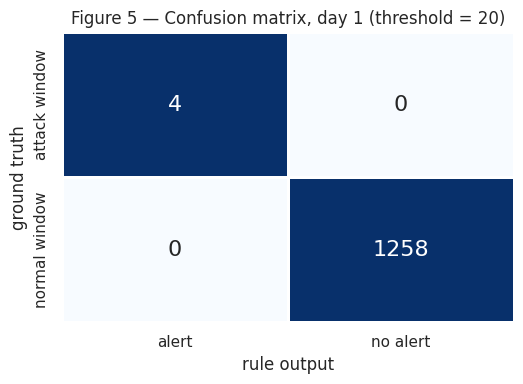

In [15]:
# ---------- Figure 5: confusion matrix (day 1) ----------------------------------------------------
cm = np.array([[tp, fn], [fp, tn]])
cm_norm = cm / cm.sum(axis=1, keepdims=True)                # colour = share inside each real class

fig, ax = plt.subplots(figsize=(5.4, 4))
sns.heatmap(cm_norm, annot=cm, fmt="d", cmap="Blues", vmin=0, vmax=1, cbar=False,
            xticklabels=["alert", "no alert"], yticklabels=["attack window", "normal window"],
            annot_kws={"size": 16}, linewidths=1, linecolor="white", ax=ax)
ax.set_title(f"Figure 5 — Confusion matrix, day 1 (threshold = {THRESHOLD})")
ax.set_xlabel("rule output")
ax.set_ylabel("ground truth")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig5_confusion.png", dpi=170, bbox_inches="tight")
plt.show()

### 8.1 Why the rule uses the 404 count and not the request count (comparison)
Same threshold (20), same data, two candidate features. This is the experiment that justifies the design.

In [16]:
rows = []
for name, feat in [("Rule A: requests / min > 20  (volume)", "n_req"),
                   ("Rule B: 404 errors / min > 20  (chosen)", "n_404")]:
    t_p, f_p, f_n, t_n = confusion(w1, feat, THRESHOLD)
    m = metrics(t_p, f_p, f_n, t_n)
    rows.append({"rule": name, "TP": t_p, "FP": f_p, "FN": f_n, "TN": t_n,
                 "precision": round(m["precision"], 3), "recall": round(m["recall"], 3), "F1": round(m["f1"], 3)})
cmp_df = pd.DataFrame(rows)
display(cmp_df)

fp_who = w1[(w1.n_req > THRESHOLD) & (w1.n_attack == 0)]
print("Who triggers the false alarms of Rule A?", dict(fp_who.actor.value_counts()))

,rule,TP,FP,FN,TN,precision,recall,F1
0,Rule A: requests / min > 20 (volume),4,8,0,1250,0.333,1.0,0.5
1,Rule B: 404 errors / min > 20 (chosen),4,0,0,1258,1.000,1.0,1.0


Who triggers the false alarms of Rule A? {'crawler': np.int64(5), 'visitor': np.int64(3)}


### 8.2 Sensitivity to the threshold
A good rule should not depend on one lucky number. We sweep the threshold from 0 to 300 and record precision, recall and the error counts.

Largest 404 count in a NORMAL window  : 12
Smallest 404 count in an ATTACK window: 65
Thresholds giving 0 FP and 0 FN        : T = 12 ... 64   (chosen T = 20)


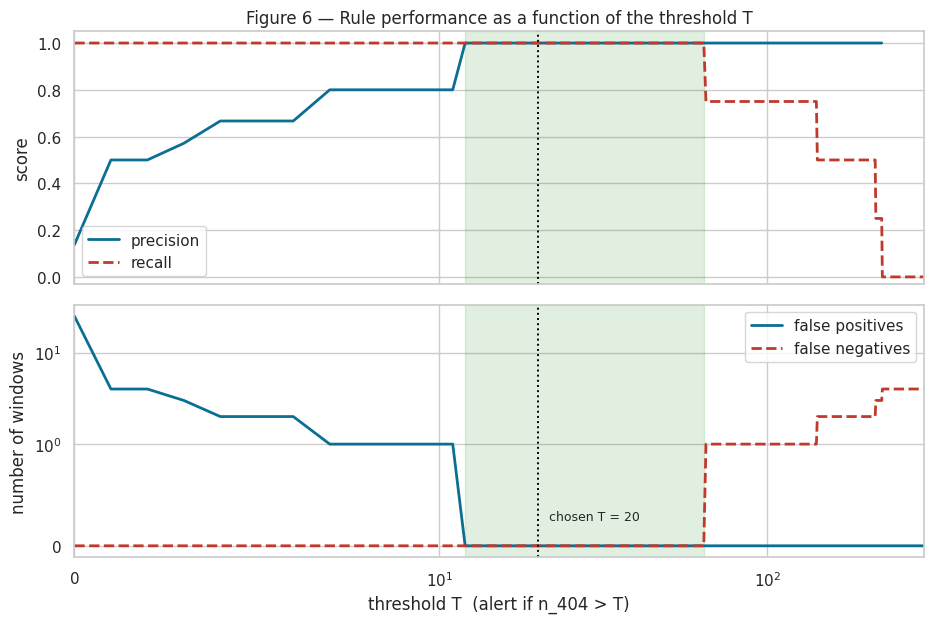

In [17]:
rows = []
for T in range(0, 301):
    a, b, c, e = confusion(w1, "n_404", T)
    rows.append(dict(T=T, TP=a, FP=b, FN=c, TN=e, **metrics(a, b, c, e)))
sweep = pd.DataFrame(rows)

perfect = sweep[(sweep.FP == 0) & (sweep.FN == 0)]["T"]
lo, hi = int(perfect.min()), int(perfect.max())
max_normal_404 = int(w1[w1.n_attack == 0]["n_404"].max())
min_attack_404 = int(w1[w1.n_attack > 0]["n_404"].min())
print(f"Largest 404 count in a NORMAL window  : {max_normal_404}")
print(f"Smallest 404 count in an ATTACK window: {min_attack_404}")
print(f"Thresholds giving 0 FP and 0 FN        : T = {lo} ... {hi}   (chosen T = {THRESHOLD})")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9.5, 6.4), sharex=True)
ax1.plot(sweep["T"], sweep["precision"], label="precision", color=BLUE, lw=2)
ax1.plot(sweep["T"], sweep["recall"], label="recall", color=RED, lw=2, ls="--")
ax1.set_ylim(-0.03, 1.05); ax1.set_ylabel("score"); ax1.legend(loc="lower left")
ax1.set_title("Figure 6 — Rule performance as a function of the threshold T")
ax2.plot(sweep["T"], sweep["FP"], label="false positives", color=BLUE, lw=2)
ax2.plot(sweep["T"], sweep["FN"], label="false negatives", color=RED, lw=2, ls="--")
ax2.set_yscale("symlog", linthresh=1); ax2.set_ylabel("number of windows"); ax2.legend(loc="upper right")
for ax in (ax1, ax2):
    ax.axvspan(lo, hi, color="green", alpha=0.12)
    ax.axvline(THRESHOLD, color="black", ls=":", lw=1.4)
ax2.set_xscale("symlog", linthresh=10); ax2.set_xlim(0, 300)
ax2.set_xlabel("threshold T  (alert if n_404 > T)")
ax2.text(THRESHOLD * 1.08, ax2.get_ylim()[0] * 3 if ax2.get_ylim()[0] > 0 else 0.25, f"chosen T = {THRESHOLD}", fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig6_threshold_sweep.png", dpi=170, bbox_inches="tight")
plt.show()

**Reading Figure 6.** The green band is the range of thresholds with *zero* errors. To its left, the threshold is too low and normal windows (e.g. the broken page) trigger false alarms (precision drops). To its right, the threshold becomes higher than some scan minutes and the attack is progressively missed (the weakest, partial last minute of the scan is lost first; recall reaches 0 above the strongest minute). T = 20 sits comfortably inside the band, so the result does not depend on a lucky choice.

*Honesty note:* this band is measured on simulated data we designed, so it proves the **logic** of the rule, not its performance on a real network. On real logs the threshold must be calibrated on a historical baseline (for example the 99.9th percentile of `n_404` per IP per minute) — see the limitations below.

## 9. Main findings (Task 9)

In [18]:
atk_rate = len(atk) / dur
summary = f"""
SUMMARY OF FINDINGS
-------------------
Data            : 2 simulated days of web-server logs in Apache combined format
                  day 1 = {len(d1)} requests ({len(atk)} injected attack requests), day 2 = {len(d2)} requests (normal only)
Anomaly         : directory-enumeration scan from {ATTACKER_IP}, {a_start.time()} -> {a_end.time()} ({dur:.0f} s, ~{atk_rate:.1f} req/s),
                  {(atk.status == 404).mean():.1%} of its requests answered 404, {int((atk.status != 404).sum())} guesses found something
Key signal      : 404 errors per IP per minute (background <= {max_normal_404}, attack windows >= {min_attack_404})
Detection rule  : alert if one IP gets > {THRESHOLD} HTTP 404 in 1 minute
Day 1 (attack)  : TP={tp} FP={fp} FN={fn} TN={tn} | precision={mA['precision']:.2f} recall={mA['recall']:.2f} F1={mA['f1']:.2f}
Day 2 (normal)  : {len(alerts2)} alerts on {len(w2)} windows -> no false alarm
Volume rule     : 'requests/min > {THRESHOLD}' gives {int(cmp_df.loc[0, 'FP'])} false positives (benign crawler and busy visitors) -> worse than the 404 rule
Detection delay : alert {delay:.0f} s after the attack began (rule evaluated each time a 1-minute window closes)
"""
print(summary)

# keep the key numbers for the written report
results = dict(
    day1_requests=len(d1), day2_requests=len(d2), attack_requests=len(atk), attack_seconds=round(dur, 1),
    attack_rate=round(atk_rate, 2), attack_404_share=round(float((atk.status == 404).mean()), 4),
    attack_hits=int((atk.status != 404).sum()), windows_day1=len(w1), windows_day2=len(w2),
    TP=tp, FP=fp, FN=fn, TN=tn, precision=mA["precision"], recall=mA["recall"], fpr=mA["fpr"], f1=mA["f1"],
    day2_alerts=len(alerts2), day2_max_404=int(w2.n_404.max()), max_normal_404=max_normal_404,
    min_attack_404=min_attack_404, safe_lo=lo, safe_hi=hi, delay_s=delay,
    volume_rule_fp=int(cmp_df.loc[0, "FP"]), volume_rule_precision=float(cmp_df.loc[0, "precision"]),
    ip_tp=ip_tp, ip_fp=ip_fp, ip_fn=ip_fn, ip_tn=ip_tn, n_ips_day1=len(all_ips),
    total_404_day1=int((d1.status == 404).sum()),
)
json.dump(results, open(DATA_DIR / "results.json", "w"), indent=2)


SUMMARY OF FINDINGS
-------------------
Data            : 2 simulated days of web-server logs in Apache combined format
                  day 1 = 8774 requests (654 injected attack requests), day 2 = 7799 requests (normal only)
Anomaly         : directory-enumeration scan from 198.51.100.23, 03:12:25 -> 03:15:21 (176 s, ~3.7 req/s),
                  98.6% of its requests answered 404, 9 guesses found something
Key signal      : 404 errors per IP per minute (background <= 12, attack windows >= 65)
Detection rule  : alert if one IP gets > 20 HTTP 404 in 1 minute
Day 1 (attack)  : TP=4 FP=0 FN=0 TN=1258 | precision=1.00 recall=1.00 F1=1.00
Day 2 (normal)  : 0 alerts on 1216 windows -> no false alarm
Volume rule     : 'requests/min > 20' gives 8 false positives (benign crawler and busy visitors) -> worse than the 404 rule
Detection delay : alert 35 s after the attack began (rule evaluated each time a 1-minute window closes)



### Interpretation

1. **The anomaly is visible and localisable.** A ~3-minute burst at night, one source IP, ~650 requests, ~99 % answered *404*. It is the only event of the day that stands out in the 404 time series (Fig. 1), the status-by-hour heatmap (Fig. 2) and the per-IP ranking (Fig. 3).
2. **The right feature matters more than the right threshold.** Total volume is a blunt signal (a harmless crawler is also "loud", so a volume threshold low enough for slower scans fires on it); the number of 404 per IP per minute separates them (Fig. 4, Section 8.1).
3. **The rule is simple and explainable**: one counter, one window, one threshold. It catches every attack window, raises no false alarm on the other windows of day 1, and raises none on an independent normal day.
4. **Detection is not the end.** The log shows the attacker found `/admin` (302), `/login` (200) and `403` responses for `/backup.zip` and `/.env`. A real response would block the IP, check whether `/admin` and `/login` are exposed on purpose, and confirm that the `403` files really are protected.

### Limitations (what we would say honestly in the defence)
- **Simulated data.** It proves that the logic works, not that the threshold is right for a real server; real thresholds must come from a baseline.
- **Low-and-slow scans.** An attacker sending fewer than 20 wrong paths per minute would evade this rule. Countermeasure: a second rule on a longer window (e.g. > 100 per hour).
- **Fixed window boundaries.** A burst split across two minutes (e.g. 15 + 15) escapes a tumbling window. Countermeasure: a sliding window.
- **Source-IP based.** A distributed scan (many IPs, few requests each) or a shared NAT address would break the "one IP = one actor" assumption.
- **The user-agent was not used** on purpose: `gobuster/3.6` is trivial to spoof, so a rule based on it would be easy to bypass.

### Possible improvements (links with the next chapter of the course)
Add the number of *distinct* 404 paths and the 404 *ratio* as features; learn a per-IP baseline; use an anomaly-detection model (Isolation Forest, Z-score) on the window table `w1`; send the alert to a SIEM and trigger an automatic block (e.g. `fail2ban`).